In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import os

print(os.listdir('/content'))

['.config', 'MachineLearningCSV.zip', 'sample_data']


In [6]:
import zipfile
import os

zip_path = "/content/MachineLearningCSV.zip"
extract_path = "/content/CICIDS2017"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

csv_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:", len(csv_files))

for file in sorted(csv_files):
    print(file)

CSV files found: 8
/content/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv


In [5]:
import os
import zipfile

path = "/content/MachineLearningCSV.zip"

print("File exists:", os.path.exists(path))
print("File size (MB):", round(os.path.getsize(path) / (1024**2), 2))
print("Valid ZIP:", zipfile.is_zipfile(path))

with open(path, "rb") as f:
    print("First 100 bytes:", f.read(100))

File exists: True
File size (MB): 224.21
Valid ZIP: True
First 100 bytes: b'PK\x03\x04\n\x00\x00\x00\x00\x00\xd5\x83\xc7L\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x13\x00\x1c\x00MachineLearningCVE/UT\t\x00\x03\xe1\x87\x19[\xf0\x87\x19[ux\x0b\x00\x01\x04\xe9\x03\x00\x00\x04\xe9\x03\x00\x00PK\x03\x04\x14\x00\x00\x00\x08\x00T\x83\xc7L\nG\xf2\xe1\x03\xf1\x8f\x03;'


In [7]:
import pandas as pd
import numpy as np
import os

csv_files = sorted(csv_files)

sampled_frames = []

for file in csv_files:
    print("Loading:", os.path.basename(file))

    df_part = pd.read_csv(
        file,
        encoding="latin1",
        low_memory=False
    )

    df_part.columns = df_part.columns.str.strip()

    # Sample up to 12,500 records per file
    n = min(12500, len(df_part))

    df_part = df_part.sample(
        n=n,
        random_state=42
    )

    sampled_frames.append(df_part)

df = pd.concat(sampled_frames, ignore_index=True)

print("\nCombined dataset shape:", df.shape)
print("\nColumns:", len(df.columns))

display(df.head())

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Combined dataset shape: (100000, 79)

Columns: 79


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,9392887,4,0,24,0,6,6,6.000000,0.000000,...,20,1.982000e+03,0.0000,1982,1982,9390905.0,0.0000,9390905,9390905,DDoS
1,64007,5438011,1,5,6,30,6,6,6.000000,0.000000,...,20,2.715100e+04,0.0000,27151,27151,5410860.0,0.0000,5410860,5410860,BENIGN
2,80,115615609,20,15,1728,3463,578,0,86.400000,211.017934,...,32,1.609163e+05,134508.6864,566475,120118,10100000.0,46752.4843,10100000,9988018,BENIGN
3,80,9827,3,5,26,11601,20,0,8.666667,10.263203,...,20,0.000000e+00,0.0000,0,0,0.0,0.0000,0,0,DDoS
4,53315,87583370,7,9,11607,62,4380,0,1658.142857,1762.272815,...,20,4.219842e+06,0.0000,4219842,4219842,82600000.0,0.0000,82600000,82600000,BENIGN


In [8]:
print("Available columns:")
print(df.columns.tolist())

print("\nAttack category distribution:")
print(df["Label"].value_counts(dropna=False))

Available columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Coun

In [9]:
df["Label"] = df["Label"].astype(str).str.strip()

df["Binary_Label"] = (
    df["Label"].str.upper() != "BENIGN"
).astype(int)

print("Binary classification distribution:")
print(df["Binary_Label"].value_counts())

print("\nClass mapping:")
print("0 = BENIGN")
print("1 = ATTACK")

Binary classification distribution:
Binary_Label
0    80629
1    19371
Name: count, dtype: int64

Class mapping:
0 = BENIGN
1 = ATTACK


In [10]:
print("Dataset shape:", df.shape)

print("Missing values:", df.isnull().sum().sum())

print("Binary classes:", df["Binary_Label"].unique())

print("Attack types:")
print(df["Label"].unique())

Dataset shape: (100000, 80)
Missing values: 28
Binary classes: [1 0]
Attack types:
['DDoS' 'BENIGN' 'PortScan' 'Bot' 'Web Attack ï¿½ Brute Force'
 'Web Attack ï¿½ XSS' 'Web Attack ï¿½ Sql Injection' 'SSH-Patator'
 'FTP-Patator' 'DoS Hulk' 'DoS Slowhttptest' 'DoS GoldenEye'
 'DoS slowloris' 'Heartbleed']


In [11]:
import numpy as np
import pandas as pd

# Preserve a copy of the original sampled data
df_clean = df.copy()

# Remove duplicate records
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Remove non-feature labels from input data
X = df_clean.drop(columns=["Label", "Binary_Label"])
y = df_clean["Binary_Label"].astype(int)

# Keep numerical features only
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinity with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

print("Original records:", before)
print("Records after duplicate removal:", len(df_clean))
print("Number of input features:", X.shape[1])
print("Remaining missing values:", X.isna().sum().sum())

print("\nClass distribution:")
print(y.value_counts())

Original records: 100000
Records after duplicate removal: 97098
Number of input features: 78
Remaining missing values: 136

Class distribution:
Binary_Label
0    78928
1    18170
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

# 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training records: 67968
Validation records: 14565
Testing records: 14565

Training distribution:
Binary_Label
0    55249
1    12719
Name: count, dtype: int64

Testing distribution:
Binary_Label
0    11840
1     2725
Name: count, dtype: int64


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def make_preprocessor():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

print("Preprocessing pipeline ready.")
print("Missing values will be filled with training medians.")
print("Feature scaling will use training data statistics.")

Preprocessing pipeline ready.
Missing values will be filled with training medians.
Feature scaling will use training data statistics.


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC

def make_model(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", estimator)
    ])

models = {
    "Logistic Regression": make_model(
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Decision Tree": make_model(
        DecisionTreeClassifier(
            max_depth=15, random_state=42
        )
    ),
    "Random Forest": make_model(
        RandomForestClassifier(
            n_estimators=100,
            n_jobs=-1,
            random_state=42
        )
    ),
    "Gradient Boosting": make_model(
        HistGradientBoostingClassifier(
            max_iter=100,
            random_state=42
        )
    ),
    "Linear SVM": make_model(
        LinearSVC(max_iter=5000, random_state=42)
    )
}

print("Models ready:")
for name in models:
    print("-", name)

Models ready:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- Linear SVM


In [15]:
import time
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    start = time.time()

    model.fit(X_train, y_train)

    duration = time.time() - start
    predictions = model.predict(X_val)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "FPR": fp / (fp + tn) if (fp + tn) else 0,
        "Training Time (s)": round(duration, 2)
    })

    trained_models[name] = model
    print(f"{name} completed.")

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "F1", ascending=False
    ).round(4)
)


Training Logistic Regression...
Logistic Regression completed.

Training Decision Tree...
Decision Tree completed.

Training Random Forest...
Random Forest completed.

Training Gradient Boosting...
Gradient Boosting completed.

Training Linear SVM...
Linear SVM completed.


,Model,Accuracy,Precision,Recall,F1,FPR,Training Time (s)
3,Gradient Boosting,0.9985,0.9960,0.9960,0.9960,0.0009,7.17
1,Decision Tree,0.9977,0.9934,0.9941,0.9938,0.0015,15.63
2,Random Forest,0.9975,0.9956,0.9908,0.9932,0.0010,21.12
4,Linear SVM,0.9529,0.8728,0.8760,0.8744,0.0294,81.73
0,Logistic Regression,0.9483,0.8465,0.8841,0.8649,0.0369,15.36


In [16]:
# Select the highest-recall model satisfying FPR <= 1%
eligible = results_df[results_df["FPR"] <= 0.01]

if eligible.empty:
    raise ValueError("No model satisfies the FPR requirement.")

selected = eligible.sort_values(
    ["Recall", "F1"],
    ascending=[False, False]
).iloc[0]

best_name = selected["Model"]
best_model = trained_models[best_name]

print("Selected model:", best_name)
print("Validation recall:", round(selected["Recall"], 4))
print("Validation FPR:", round(selected["FPR"], 4))

Selected model: Gradient Boosting
Validation recall: 0.996
Validation FPR: 0.0009


In [17]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

test_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print("Test accuracy:", accuracy_score(y_test, test_pred))
print("Test precision:", precision_score(y_test, test_pred))
print("Test recall:", recall_score(y_test, test_pred))
print("Test F1-score:", f1_score(y_test, test_pred))

print("\nClassification report:")
print(classification_report(
    y_test, test_pred,
    target_names=["BENIGN", "ATTACK"]
))

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Test false-positive rate:", fp / (fp + tn))
print("Confusion matrix:")
print(cm)

Selected model: Gradient Boosting
Test accuracy: 0.9985581874356334
Test precision: 0.9945135332845647
Test recall: 0.9977981651376147
Test F1-score: 0.9961531416010259

Classification report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     11840
      ATTACK       0.99      1.00      1.00      2725

    accuracy                           1.00     14565
   macro avg       1.00      1.00      1.00     14565
weighted avg       1.00      1.00      1.00     14565

Test false-positive rate: 0.001266891891891892
Confusion matrix:
[[11825    15]
 [    6  2719]]


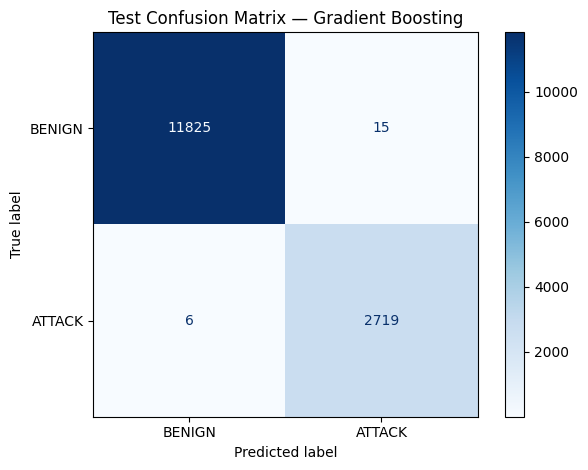

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Test Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig(
    "/content/test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [19]:
import joblib
import os

model_path = "/content/selected_model.joblib"

joblib.dump({
    "model": best_model,
    "feature_names": X_train.columns.tolist(),
    "model_name": best_name,
    "label_mapping": {0: "BENIGN", 1: "ATTACK"}
}, model_path)

print("Saved model:", model_path)
print("Model size (MB):",
      round(os.path.getsize(model_path) / 1024**2, 2))

Saved model: /content/selected_model.joblib
Model size (MB): 0.47


In [20]:
import pandas as pd

demo = X_test.sample(
    n=min(20, len(X_test)),
    random_state=42
).copy()

demo.to_csv("/content/demo_upload.csv", index=False)

print("Demo records:", len(demo))
print("Features:", len(demo.columns))
display(demo.head())

Demo records: 20
Features: 78


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
36390,443,169,2,0,12,0,6,6,6.0,0.0,...,1,20,0.0,0.0,0,0,0.0,0.0,0,0
55767,53,61076,1,1,45,97,45,45,45.0,0.0,...,0,20,0.0,0.0,0,0,0.0,0.0,0,0
22319,443,80,2,0,0,0,0,0,0.0,0.0,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0
7351,26432,3811057,1,6,6,36,6,6,6.0,0.0,...,0,20,0.0,0.0,0,0,0.0,0.0,0,0
91781,36694,31,1,1,0,0,0,0,0.0,0.0,...,0,32,0.0,0.0,0,0,0.0,0.0,0,0


In [21]:
saved = joblib.load("/content/selected_model.joblib")

predictions = saved["model"].predict(demo)

prediction_df = pd.DataFrame({
    "Record": range(1, len(predictions) + 1),
    "Prediction": [
        "ATTACK" if p == 1 else "BENIGN"
        for p in predictions
    ]
})

display(prediction_df)

print("\nPrediction summary:")
print(prediction_df["Prediction"].value_counts())

prediction_df.to_csv(
    "/content/demo_predictions.csv",
    index=False
)

,Record,Prediction
0,1,BENIGN
1,2,BENIGN
2,3,BENIGN
3,4,BENIGN
4,5,BENIGN
5,6,BENIGN
6,7,BENIGN
7,8,BENIGN
8,9,BENIGN
9,10,BENIGN



Prediction summary:
Prediction
BENIGN    19
ATTACK     1
Name: count, dtype: int64


In [22]:
import zipfile
from google.colab import files

output_files = [
    "/content/selected_model.joblib",
    "/content/demo_upload.csv",
    "/content/demo_predictions.csv",
    "/content/test_confusion_matrix.png"
]

zip_name = "/content/CSET312_Final_Outputs.zip"

with zipfile.ZipFile(
    zip_name, "w", zipfile.ZIP_DEFLATED
) as z:
    for file in output_files:
        z.write(file, arcname=os.path.basename(file))

files.download(zip_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import os
import zipfile
from google.colab import files

output_files = [
    "/content/selected_model.joblib",
    "/content/demo_upload.csv",
    "/content/demo_predictions.csv",
    "/content/test_confusion_matrix.png"
]

zip_name = "/content/CSET312_Final_Outputs.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for path in output_files:
        assert os.path.isfile(path), f"Missing file: {path}"
        z.write(path, arcname=os.path.basename(path))

print("Output package created.")
files.download(zip_name)

Output package created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>